<a href="https://colab.research.google.com/github/toshniwal-keshav/LabBioInspired/blob/main/DroneRouteOptimizationPSO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Optimal Waypoints (including Start & Goal):
  Point 0: [ 0.  0. 10.]
  Point 1: [ 0.  0. 10.]
  Point 2: [18.24 39.09 27.14]
  Point 3: [48.87 74.49 49.65]
  Point 4: [64.83 82.61 59.14]
  Point 5: [76.26 88.45 66.04]
  Point 6: [100. 100.  80.]

Final Path Cost: 163.06


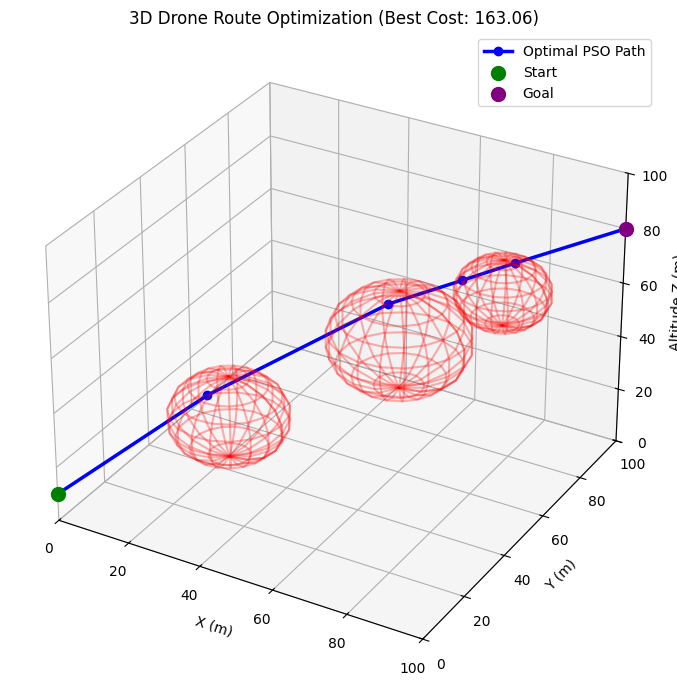

In [4]:
import numpy as np
import matplotlib.pyplot as plt

class DronePSO:
    def __init__(self, start, goal, obstacles, bounds, n_waypoints=5,
                 swarm_size=60, max_iter=150, w=0.7, c1=1.5, c2=1.5, penalty_weight=1000.0):
        self.start = np.array(start, dtype=float)
        self.goal = np.array(goal, dtype=float)
        self.obstacles = obstacles
        self.bounds = np.array(bounds, dtype=float)

        self.n_waypoints = n_waypoints
        self.swarm_size = swarm_size
        self.max_iter = max_iter

        self.w = w
        self.c1 = c1
        self.c2 = c2
        self.penalty_weight = penalty_weight

        self.positions = self._init_swarm()
        self.velocities = np.zeros_like(self.positions)

        self.p_best = self.positions.copy()
        self.p_best_cost = np.array([self.calculate_cost(p) for p in self.positions])

        best_idx = np.argmin(self.p_best_cost)
        self.g_best = self.p_best[best_idx].copy()
        self.g_best_cost = self.p_best_cost[best_idx]
        self.cost_history = list()

    def _init_swarm(self):
        swarm = np.zeros((self.swarm_size, self.n_waypoints, 3))
        t_values = np.linspace(0, 1, self.n_waypoints + 2)[1:-1]

        for i in range(self.swarm_size):
            for j, t in enumerate(t_values):
                base_point = (1 - t) * self.start + t * self.goal
                noise = np.random.uniform(-25, 25, size=3)
                swarm[i, j] = np.clip(base_point + noise, self.bounds[:, 0], self.bounds[:, 1])
        return swarm

    @staticmethod
    def _point_to_segment_distance(point, seg_start, seg_end):
        seg_vec = seg_end - seg_start
        pt_vec = point - seg_start
        seg_len_sq = np.dot(seg_vec, seg_vec)

        if seg_len_sq == 0.0:
            return np.linalg.norm(pt_vec)

        t = np.clip(np.dot(pt_vec, seg_vec) / seg_len_sq, 0.0, 1.0)
        projection = seg_start + t * seg_vec
        return np.linalg.norm(point - projection)

    def calculate_cost(self, waypoints):
        full_route = np.vstack([self.start, waypoints, self.goal])
        total_distance = 0.0
        collision_penalty = 0.0

        for i in range(len(full_route) - 1):
            p1, p2 = full_route[i], full_route[i + 1]
            total_distance += np.linalg.norm(p2 - p1)

            for obs in self.obstacles:
                center = np.array(obs['center'], dtype=float)
                safe_radius = obs['radius']
                dist = self._point_to_segment_distance(center, p1, p2)

                if dist < safe_radius:
                    violation = safe_radius - dist
                    collision_penalty += self.penalty_weight * (violation ** 2)

        return total_distance + collision_penalty

    def optimize(self):
        for iteration in range(self.max_iter):
            w_current = self.w - (self.w - 0.4) * (iteration / self.max_iter)

            for i in range(self.swarm_size):
                r1 = np.random.rand(self.n_waypoints, 3)
                r2 = np.random.rand(self.n_waypoints, 3)

                cognitive = self.c1 * r1 * (self.p_best[i] - self.positions[i])
                social = self.c2 * r2 * (self.g_best - self.positions[i])
                self.velocities[i] = w_current * self.velocities[i] + cognitive + social

                self.positions[i] = np.clip(
                    self.positions[i] + self.velocities[i],
                    self.bounds[:, 0],
                    self.bounds[:, 1]
                )

                cost = self.calculate_cost(self.positions[i])
                if cost < self.p_best_cost[i]:
                    self.p_best[i] = self.positions[i].copy()
                    self.p_best_cost[i] = cost

                    if cost < self.g_best_cost:
                        self.g_best = self.positions[i].copy()
                        self.g_best_cost = cost

            self.cost_history.append(self.g_best_cost)

        return np.vstack([self.start, self.g_best, self.goal]), self.g_best_cost

    def plot_route(self, best_route):
        fig = plt.figure(figsize=(10, 7))
        ax = fig.add_subplot(111, projection='3d')

        u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:10j]
        for obs in self.obstacles:
            cx, cy, cz = obs['center']
            r = obs['radius']
            x = cx + r * np.cos(u) * np.sin(v)
            y = cy + r * np.sin(u) * np.sin(v)
            z = cz + r * np.cos(v)
            ax.plot_wireframe(x, y, z, color='red', alpha=0.3)

        ax.plot(best_route[:, 0], best_route[:, 1], best_route[:, 2],
                color='blue', linewidth=2.5, marker='o', label='Optimal PSO Path')

        ax.scatter(*self.start, color='green', s=100, label='Start')
        ax.scatter(*self.goal, color='purple', s=100, label='Goal')

        ax.set_xlim(self.bounds[0])
        ax.set_ylim(self.bounds[1])
        ax.set_zlim(self.bounds[2])
        ax.set_xlabel('X (m)')
        ax.set_ylabel('Y (m)')
        ax.set_zlabel('Altitude Z (m)')
        ax.set_title(f'3D Drone Route Optimization (Best Cost: {self.g_best_cost:.2f})')
        ax.legend()
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    np.random.seed(42)

    # Using tuples (x, y, z) so coordinates copy cleanly
    start_point = (0, 0, 10)
    goal_point = (100, 100, 80)
    airspace_bounds = ((0, 100), (0, 100), (0, 100))

    no_fly_zones = [
        {'center': (30, 30, 30), 'radius': 15},
        {'center': (60, 60, 50), 'radius': 18},
        {'center': (80, 75, 65), 'radius': 12}
    ]

    pso_drone = DronePSO(
        start=start_point,
        goal=goal_point,
        obstacles=no_fly_zones,
        bounds=airspace_bounds,
        n_waypoints=5,
        swarm_size=80,
        max_iter=200
    )

    optimal_path, final_cost = pso_drone.optimize()

    print("Optimal Waypoints (including Start & Goal):")
    for idx, pt in enumerate(optimal_path):
        print(f"  Point {idx}: {np.round(pt, 2)}")
    print(f"\nFinal Path Cost: {final_cost:.2f}")

    pso_drone.plot_route(optimal_path)